sigma range used: [4.0, 40.0], 25 scales (geometric), threshold=0.05
676 blobs detected. Largest 5 circles (x, y, radius):
  centre=(83, 1), r=56.6px, sigma=40.0
  centre=(124, 2), r=56.6px, sigma=40.0
  centre=(359, 38), r=56.6px, sigma=40.0
  centre=(342, 0), r=56.6px, sigma=40.0
  centre=(242, 0), r=51.4px, sigma=36.3


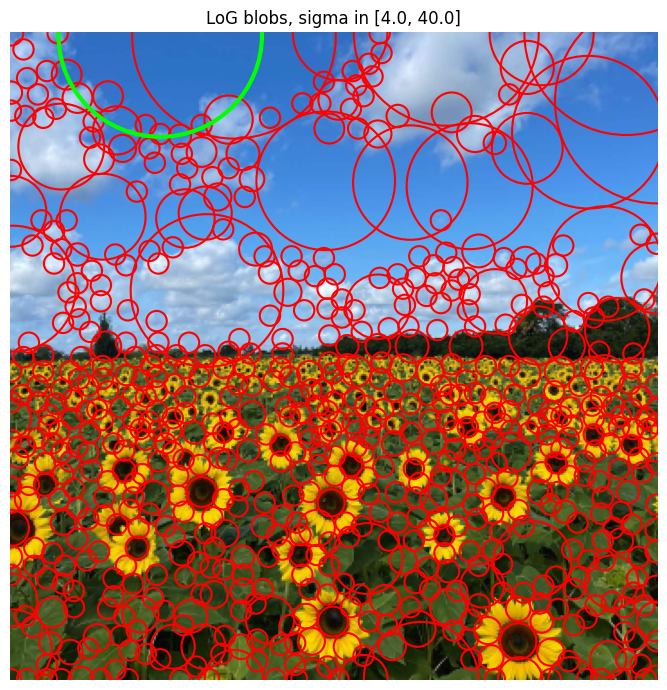

In [5]:
"""Q1: Blob detection with scale-normalised Laplacian of Gaussian (LoG) + scale-space extrema.
No cv2.HoughCircles used."""
import cv2 as cv
import numpy as np
from scipy.ndimage import maximum_filter

im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, "Image not found - check the path"
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

# ---- scale space parameters (tune these and REPORT them) ----
sigma_min, sigma_max, n_scales = 4.0, 40.0, 25
sigmas = np.geomspace(sigma_min, sigma_max, n_scales)
threshold = 0.05          # on |scale-normalised LoG|; tune by looking at results

# ---- build scale-space of scale-normalised LoG responses ----
stack = []
for s in sigmas:
    g = cv.GaussianBlur(gray, (0, 0), s)
    log = cv.Laplacian(g, cv.CV_32F, ksize=3)
    stack.append((s ** 2) * log)          # sigma^2 normalisation
stack = np.stack(stack, axis=0)           # (n_scales, H, W)
resp = np.abs(stack)  # use -stack instead if you only want bright blobs on dark bg

# ---- 3D local maxima (x, y, sigma) ----
local_max = (resp == maximum_filter(resp, size=(3, 3, 3))) & (resp > threshold)
si, ys, xs = np.nonzero(local_max)
blobs = [(x, y, sigmas[i] * np.sqrt(2), resp[i, y, x]) for i, y, x in zip(si, ys, xs)]  # r = sqrt(2)*sigma

# ---- simple non-maximum suppression of heavily overlapping circles ----
blobs.sort(key=lambda b: -b[3])
kept = []
for b in blobs:
    ok = True
    for k in kept:
        d = np.hypot(b[0] - k[0], b[1] - k[1])
        if d < 0.7 * max(b[2], k[2]):     # centres too close -> same blob
            ok = False
            break
    if ok:
        kept.append(b)

# ---- draw ----
import matplotlib.pyplot as plt

kept_by_size = sorted(kept, key=lambda b: -b[2])
print(f"sigma range used: [{sigma_min}, {sigma_max}], {n_scales} scales (geometric), threshold={threshold}")
print(f"{len(kept)} blobs detected. Largest 5 circles (x, y, radius):")
for x, y, r, _ in kept_by_size[:5]:
    print(f"  centre=({x}, {y}), r={r:.1f}px, sigma={r / np.sqrt(2):.1f}")

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))      # BGR -> RGB for matplotlib
for x, y, r, _ in kept:
    ax.add_patch(plt.Circle((x, y), r, color='r', fill=False, linewidth=1.5))
x, y, r, _ = kept_by_size[0]                       # highlight the largest
ax.add_patch(plt.Circle((x, y), r, color='lime', fill=False, linewidth=3))
ax.set_title(f'LoG blobs, sigma in [{sigma_min}, {sigma_max}]')
ax.axis('off')
plt.tight_layout()
plt.show()

RANSAC sample line (a,b,d): (np.float64(-0.7057949168140225), np.float64(-0.7084162162171945), np.float64(-1.5366783902920282))  inliers: 61
Refined line (a,b,d): [-0.71530102 -0.69881647 -1.42941432]  ||[a,b]|| = 1.0
RANSAC sample circle (cx,cy,r): (np.float64(1.7639949078724222), np.float64(2.944039369569126), np.float64(9.869212313550083))  inliers: 38
Refined circle (cx,cy,r): [1.85622815 3.03067579 9.91032759]   (ground truth: 2, 3, 10)

Circle-first: inliers = 57  params: (np.float64(1.7716159134306344), np.float64(3.1493077471120507), np.float64(9.978760548321931))


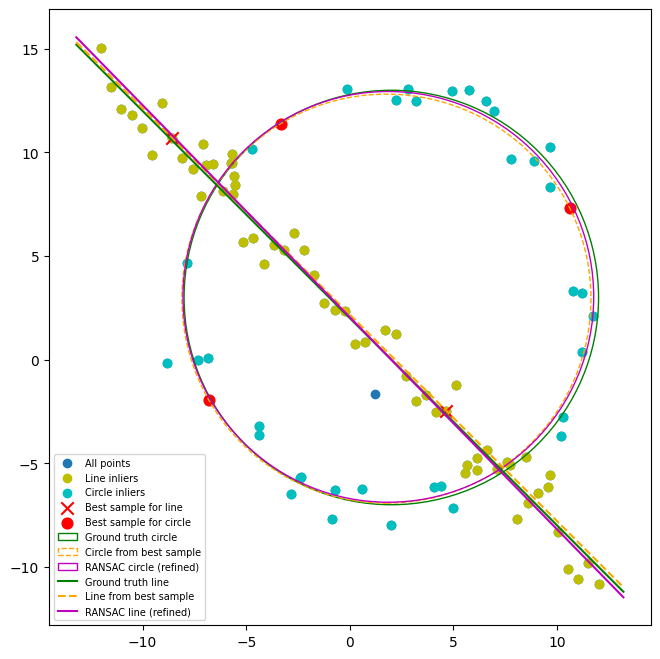

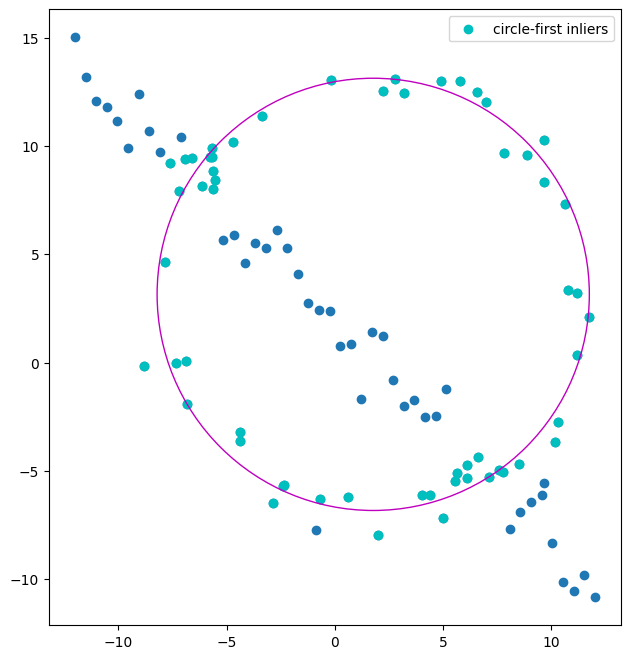

In [7]:
"""Q2: RANSAC line then circle (own implementation), with scipy.optimize.minimize refinement."""
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# np.random.seed(0)   # uncomment for reproducible results
# ------------------ data generation (from the assignment) ------------------
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))

# ------------------ line model ------------------
def line_from_two(p1, p2):
    d = p2 - p1
    nrm = np.array([-d[1], d[0]])
    nrm /= np.linalg.norm(nrm)            # ||[a,b]|| = 1
    return nrm[0], nrm[1], nrm @ p1       # a, b, d  with a x + b y = d

def line_err(params, P):
    a, b_, d = params
    return np.abs(P @ np.array([a, b_]) - d)   # normal distance (valid since unit normal)

def refine_line(P):
    """Total least squares with constraint a^2+b^2=1 via scipy.minimize."""
    def cost(p):
        return np.sum((P @ p[:2] - p[2]) ** 2)
    # init from SVD (TLS closed form) for a good start
    c = P.mean(0)
    _, _, Vt = np.linalg.svd(P - c)
    nrm = Vt[-1]
    p0 = np.array([nrm[0], nrm[1], nrm @ c])
    cons = {'type': 'eq', 'fun': lambda p: p[0] ** 2 + p[1] ** 2 - 1}
    res = minimize(cost, p0, constraints=cons, method='SLSQP')
    return res.x

def ransac_line(P, iters=1000, thresh=1.5, min_inliers=30):
    best, best_in, best_sample = None, np.zeros(len(P), bool), None
    for _ in range(iters):
        idx = np.random.choice(len(P), 2, replace=False)
        p = line_from_two(P[idx[0]], P[idx[1]])
        inl = line_err(p, P) < thresh
        if inl.sum() > best_in.sum() and inl.sum() >= min_inliers:
            best, best_in, best_sample = p, inl, idx
    return best, best_in, best_sample

# ------------------ circle model ------------------
def circle_from_three(p1, p2, p3):
    A = np.array([[p2[0] - p1[0], p2[1] - p1[1]],
                  [p3[0] - p1[0], p3[1] - p1[1]]]) * 2
    if abs(np.linalg.det(A)) < 1e-6:
        return None                        # collinear
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    c = np.linalg.solve(A, rhs)
    return c[0], c[1], np.linalg.norm(p1 - c)

def circle_err(params, P):
    cx, cy, rr = params
    return np.abs(np.hypot(P[:, 0] - cx, P[:, 1] - cy) - rr)   # radial error

def refine_circle(P, p0):
    cost = lambda p: np.sum((np.hypot(P[:, 0] - p[0], P[:, 1] - p[1]) - p[2]) ** 2)
    return minimize(cost, p0, method='Nelder-Mead').x

def ransac_circle(P, iters=2000, thresh=1.2, min_inliers=25):
    best, best_in, best_sample = None, np.zeros(len(P), bool), None
    for _ in range(iters):
        idx = np.random.choice(len(P), 3, replace=False)
        p = circle_from_three(*P[idx])
        if p is None:
            continue
        inl = circle_err(p, P) < thresh
        if inl.sum() > best_in.sum() and inl.sum() >= min_inliers:
            best, best_in, best_sample = p, inl, idx
    return best, best_in, best_sample

# ------------------ (a) line first ------------------
line_p, line_in, line_s = ransac_line(X)
line_ref = refine_line(X[line_in])
print("RANSAC sample line (a,b,d):", line_p, " inliers:", line_in.sum())
print("Refined line (a,b,d):", line_ref, " ||[a,b]|| =", np.linalg.norm(line_ref[:2]))

# ------------------ (b) remove line consensus, fit circle ------------------
rem = X[~line_in]
circ_p, circ_in, circ_s = ransac_circle(rem)
circ_ref = refine_circle(rem[circ_in], np.array(circ_p))
print("RANSAC sample circle (cx,cy,r):", circ_p, " inliers:", circ_in.sum())
print("Refined circle (cx,cy,r):", circ_ref, "  (ground truth: 2, 3, 10)")

# ------------------ (c) plot ------------------
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, c='tab:blue', label='All points')
ax.scatter(*X[line_in].T, c='y', label='Line inliers')
ax.scatter(*rem[circ_in].T, c='c', label='Circle inliers')
ax.scatter(*X[line_s].T, c='r', marker='x', s=80, label='Best sample for line')
ax.scatter(*rem[circ_s].T, c='r', s=60, label='Best sample for circle')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.add_patch(plt.Circle(circ_p[:2], circ_p[2], color='orange', fill=False, ls='--', label='Circle from best sample'))
ax.add_patch(plt.Circle(circ_ref[:2], circ_ref[2], color='m', fill=False, label='RANSAC circle (refined)'))
xs = np.array(ax.get_xlim())
ax.plot(xs, m * xs + b, 'g', label='Ground truth line')
a_, b_, d_ = line_p
ax.plot(xs, (d_ - a_ * xs) / b_, 'orange', ls='--', label='Line from best sample')
a_, b_, d_ = line_ref
ax.plot(xs, (d_ - a_ * xs) / b_, 'm', label='RANSAC line (refined)')
ax.set_aspect('equal'); ax.legend(fontsize=7)

# ------------------ (d) circle first ------------------
circ1_p, circ1_in, _ = ransac_circle(X, thresh=1.2, min_inliers=25)
print("\nCircle-first: inliers =", circ1_in.sum(), " params:", circ1_p)
rem2 = X[~circ1_in]
fig2, ax2 = plt.subplots(figsize=(8, 8))
ax2.scatter(*X.T, c='tab:blue'); ax2.scatter(*X[circ1_in].T, c='c', label='circle-first inliers')
ax2.add_patch(plt.Circle(circ1_p[:2], circ1_p[2], color='m', fill=False))
ax2.set_aspect('equal'); ax2.legend()
plt.show()

In [11]:
%matplotlib qt

In [15]:
"""Q3: Superimpose a flag on a planar surface using a homography from 4 clicked points.
Usage: python q3_homography_flag.py <architecture_image> <flag_image> [output]
Click the 4 corners in order: top-left, top-right, bottom-right, bottom-left. Then press any key."""
import sys
import cv2 as cv
import numpy as np

arch = cv.imread('a2images/wadham.jpg')
flag = cv.imread('a2images/flag.png')
assert arch is not None and flag is not None, "check image paths"

import matplotlib.pyplot as plt

# click the 4 points with matplotlib (needs an interactive backend, e.g. TkAgg / Qt5Agg)
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(cv.cvtColor(arch, cv.COLOR_BGR2RGB))
ax.set_title('Click 4 corners: TL, TR, BR, BL')
pts = plt.ginput(4, timeout=0)
plt.close(fig)

dst = np.array(pts, dtype=np.float32)
h, w = flag.shape[:2]
src = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float32)

H, _ = cv.findHomography(src, dst)          # flag -> architecture plane
print("Homography H =\n", H)
warped = cv.warpPerspective(flag, H, (arch.shape[1], arch.shape[0]))
mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, (arch.shape[1], arch.shape[0]))

alpha = 0.6                                  # blending weight of the flag
m3 = (mask[..., None] / 255.0)
blend = (arch * (1 - alpha * m3) + warped * (alpha * m3)).astype(np.uint8)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
axs[0].imshow(cv.cvtColor(arch, cv.COLOR_BGR2RGB)); axs[0].set_title('Original')
axs[0].plot(*np.vstack([dst, dst[:1]]).T, 'r-o')
axs[1].imshow(cv.cvtColor(blend, cv.COLOR_BGR2RGB)); axs[1].set_title('Flag superimposed')
for a in axs: a.axis('off')
plt.savefig('q3_output', dpi=150)
plt.tight_layout()
plt.show()

Homography H =
 [[ 3.18141505e-01 -1.60187769e-02  1.38898880e+02]
 [ 1.12426795e-01  2.97378927e-01  2.01830246e+02]
 [ 2.28801497e-04 -5.45004011e-05  1.00000000e+00]]


In [16]:
"""Q4: Align PCB images to template AECC1.jpg with SIFT + BFMatcher + RANSAC homography, then difference."""
import glob, os
import cv2 as cv
import numpy as np

template_path = 'a2images/pcbs/AECC1.jpg'                 # adjust paths
pcb_paths = sorted(p for p in glob.glob('a2images/pcbs/*.jpg')
                   if os.path.basename(p) != 'AECC1.jpg')   # all other PCB images
os.makedirs('q4_out', exist_ok=True)

tmpl = cv.imread(template_path)
tmpl_g = cv.cvtColor(tmpl, cv.COLOR_BGR2GRAY)
sift = cv.SIFT_create()
kp_t, des_t = sift.detectAndCompute(tmpl_g, None)   # (a)
bf = cv.BFMatcher()

for path in pcb_paths:
    name = os.path.splitext(os.path.basename(path))[0]
    img = cv.imread(path)
    g = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(g, None)         # (a)

    # (b) match with Lowe's ratio test, then RANSAC homography
    knn = bf.knnMatch(des, des_t, k=2)
    good = [m for m, n in knn if m.distance < 0.75 * n.distance]
    src = np.float32([kp[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp_t[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, inl = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    print(f"{name}: {len(good)} good matches, {int(inl.sum())} RANSAC inliers")
    print(H)

    vis = cv.drawMatches(img, kp, tmpl, kp_t, good, None,
                         matchesMask=inl.ravel().tolist(),
                         flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    cv.imwrite(f'q4_out/{name}_matches.png', vis)

    # (c) warp and difference
    aligned = cv.warpPerspective(img, H, (tmpl.shape[1], tmpl.shape[0]))
    diff = cv.absdiff(aligned, tmpl)
    diff_g = cv.cvtColor(diff, cv.COLOR_BGR2GRAY)
    diff_vis = cv.normalize(diff_g, None, 0, 255, cv.NORM_MINMAX)
    cv.imwrite(f'q4_out/{name}_aligned.png', aligned)
    cv.imwrite(f'q4_out/{name}_diff.png', diff_vis)
    # side-by-side panel for the report
    panel = np.hstack([tmpl, aligned, cv.cvtColor(diff_vis, cv.COLOR_GRAY2BGR)])
    cv.imwrite(f'q4_out/{name}_panel.png', panel)

AAAA1: 51 good matches, 18 RANSAC inliers
[[ 1.20047143e+00 -1.10956503e+00  1.04683946e+03]
 [ 6.42936175e-01  9.51312963e-01 -3.18155188e+02]
 [ 3.02354784e-05 -7.19433667e-05  1.00000000e+00]]
ADAD1: 369 good matches, 194 RANSAC inliers
[[ 1.22641166e+00 -1.61005817e-02 -5.78926829e+01]
 [ 1.39064566e-01  1.04971389e+00 -1.44243239e+02]
 [ 5.00335981e-05  4.37194016e-06  1.00000000e+00]]
AECC2: 4322 good matches, 3847 RANSAC inliers
[[ 1.00057628e+00 -1.50450714e-02  3.21100381e+01]
 [ 1.65924885e-02  9.99995224e-01 -1.81596023e+01]
 [ 3.48317715e-07  2.46480108e-07  1.00000000e+00]]
AECC3: 5629 good matches, 5006 RANSAC inliers
[[ 9.99611936e-01 -9.99562916e-03  2.24370938e+01]
 [ 1.04346239e-02  9.99188264e-01 -1.13615462e+01]
 [ 1.30967319e-08  1.49810661e-07  1.00000000e+00]]
AECC4: 3830 good matches, 3402 RANSAC inliers
[[ 9.99426921e-01 -1.40326572e-02  3.15510091e+01]
 [ 1.38790878e-02  9.98990943e-01 -1.39157500e+01]
 [ 8.43172267e-09  2.67791795e-07  1.00000000e+00]]
